In [1]:
import scanpy as sc
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np

from paste2 import PASTE2, projection

In [2]:
# Normalize spatial coordinates to 0-10 range for both adata1 and adata2
# Normalize x and y coordinates separately
def normalize_spatial_separately(coords, min_val=0, max_val=5000):
    normalized = coords.copy()
    for i in range(2):  # For x (0th column) and y (1st column)
        min_coord = coords[:, i].min()
        max_coord = coords[:, i].max()
        normalized[:, i] = min_val + (coords[:, i] - min_coord) * (max_val - min_val) / (max_coord - min_coord)
    return normalized




In [3]:
import scanpy as sc 

#run using env_stalign from here
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

refExpression = pd.read_csv('refSubAD_expression.csv', index_col=0)
queryExpression = pd.read_csv('querySubAD_expression.csv', index_col=0)
refObs = pd.read_csv('refSubAD_obs.csv', index_col=0)
queryObs = pd.read_csv('querySubAD_obs.csv', index_col=0)

refAD = ad.AnnData(X=refExpression.values, obs=refObs)
queryAD = ad.AnnData(X=queryExpression.values, obs=queryObs)

refAD.var_names = refExpression.columns
queryAD.var_names = queryExpression.columns


refAD.obsm['spatial'] = refAD.obs[['New_X','New_Y']].values
queryAD.obsm['spatial'] = queryAD.obs[['New_X','New_Y']].values

/home/adyprat/anaconda3/envs/paste2/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/adyprat/anaconda3/envs/paste2/lib/python3.9/site-packages/anndata/_core/aligned_df.py:68: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [4]:
refAD.obsm['X_spatial'] = refAD.obs[['New_X','New_Y']].values
queryAD.obsm['X_spatial'] = queryAD.obs[['New_X','New_Y']].values


In [5]:
refAD.write_h5ad('ref_input_RNA_tongue.h5ad')
queryAD.write_h5ad('query_input_Prot_tongue.h5ad')

In [6]:
queryAD.obsm['spatial']


array([[1624.13725104,    0.        ],
       [1892.72332873,    5.9159929 ],
       [1586.27489647,   14.98718202],
       ...,
       [2154.40741471, 3290.86965096],
       [2244.72490633, 3321.23841451],
       [2163.0842043 , 3344.50798659]])

In [7]:
refAD.obs.head()

,fov,volume,center_x,center_y,min_x,min_y,max_x,max_y,anisotropy,transcript_count,...,n_counts,transformed_x,transformed_y,in_ROI,pred_cell_type,New_X,New_Y,CellType,image_id,spatial_domain
3443715200455100055,1659,895.222590,2221.702312,855.475433,2208.208309,848.342761,2229.608301,868.950315,1.568678,18,...,18,10954.380002,13944.383429,True,Epithelial cells,3020.047524,1099.776842,Epithelial cells,ref,1
3443715200455100057,1659,563.617586,2249.628010,856.712864,2243.702992,852.422887,2257.510557,860.844804,1.631710,5,...,5,10946.573801,13890.089022,True,Epithelial cells,3012.241322,1045.482436,Epithelial cells,ref,1
3443715200455100058,1659,620.479818,2238.690499,858.371046,2231.546713,853.188508,2245.611800,863.004770,1.708316,12,...,12,10945.461033,13911.796937,True,Epithelial cells,3011.128555,1067.190351,Epithelial cells,ref,1
3443715200455100060,1659,659.589987,2263.506520,856.819628,2255.252020,848.642947,2271.876339,864.627515,1.273679,30,...,30,10943.683312,13863.000800,True,Epithelial cells,3009.350833,1018.394213,Epithelial cells,ref,1
3443715200456100090,1658,1062.222626,2372.592401,811.863378,2365.081204,802.877122,2383.640714,825.374422,1.297896,11,...,11,11010.086369,13640.624477,True,Epithelial cells,3075.753890,796.017891,Epithelial cells,ref,1


In [8]:
refAD[:,queryAD.var_names].var_names == queryAD.var_names



array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])

In [9]:
refAD

AnnData object with n_obs × n_vars = 3608 × 16
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'Anti-Chicken_raw', 'Anti-Chicken_high_pass', 'PolyT_raw', 'PolyT_high_pass', 'Cellbound2_raw', 'Cellbound2_high_pass', 'Anti-Human_raw', 'Anti-Human_high_pass', 'DAPI_raw', 'DAPI_high_pass', 'Anti-Rat_raw', 'Anti-Rat_high_pass', 'Anti-Mouse_raw', 'Anti-Mouse_high_pass', 'Cellbound3_raw', 'Cellbound3_high_pass', 'Cellbound1_raw', 'Cellbound1_high_pass', 'Anti-Goat_raw', 'Anti-Goat_high_pass', 'Anti-Rabbit_raw', 'Anti-Rabbit_high_pass', 'DAPI_raw_log', 'n_counts', 'transformed_x', 'transformed_y', 'in_ROI', 'pred_cell_type', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain'
    obsm: 'spatial', 'X_spatial'

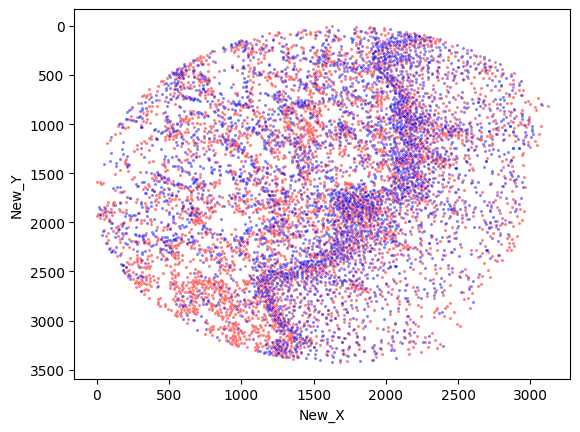

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.scatterplot(x=queryAD.obs['New_X'],y=queryAD.obs['New_Y'],s=5, color='red', alpha=0.5)
sns.scatterplot(x=refAD.obs['New_X'],y=refAD.obs['New_Y'],s=5, color='blue', alpha=0.5)
plt.gca().invert_yaxis()

In [11]:
# Convert scaled values in queryAD.X to counts by reversing scaling (if possible).
# If you know the scaling parameters (mean, std, min, max, etc.), you can invert the transformation.
# If not, a common approach is to exponentiate if log1p was used, or rescale to integers.
# Here, we'll assume log1p was used (common in scRNA-seq), so we invert with expm1 and round to integers.

import numpy as np

# If queryAD.X is a sparse matrix, convert to dense for transformation
if hasattr(queryAD.X, "toarray"):
    X_dense = queryAD.X.toarray()
else:
    X_dense = queryAD.X

# Invert log1p transformation (if that was the scaling used)
X_counts = np.expm1(X_dense)
X_counts[X_counts < 0] = 0  # Ensure no negative counts

queryAD.X = X_counts


In [12]:
sc.pp.normalize_total(queryAD, target_sum=1e2)
sc.pp.normalize_total(refAD, target_sum=1e2)


/home/adyprat/anaconda3/envs/paste2/lib/python3.9/site-packages/scanpy/preprocessing/_normalization.py:234: UserWarning: Some cells have zero counts
  warn(UserWarning("Some cells have zero counts"))


In [13]:
queryAD.var_names

Index(['CD8A', 'CD4', 'GZMB', 'MKI67', 'LGALS3', 'CD3E', 'PTPRC', 'PDCD1',
       'MPO', 'CD68', 'PDPN', 'ACTA2', 'CD34', 'HLA-DRA', 'CD38', 'KRT4'],
      dtype='object')

In [14]:
queryAD.X.min(), refAD.X.min()

(np.float64(0.0), np.float32(0.0))

In [15]:
refAD.shape, queryAD.shape

((3608, 16), (4671, 16))

In [17]:
pi_AB = PASTE2.partial_pairwise_align(queryAD,refAD, s=0.99)


PASTE2 starts...
Starting GLM-PCA...
Iteration: 0 | deviance=2.1650E+6
Iteration: 1 | deviance=2.1640E+6
Iteration: 2 | deviance=2.0375E+5
Iteration: 3 | deviance=3.1084E+4
Iteration: 4 | deviance=1.6084E+4
Iteration: 5 | deviance=1.1116E+4
Iteration: 6 | deviance=8.6982E+3
Iteration: 7 | deviance=7.2758E+3
Iteration: 8 | deviance=6.3401E+3
Iteration: 9 | deviance=5.6765E+3
Iteration: 10 | deviance=5.1806E+3
Iteration: 11 | deviance=4.7955E+3
Iteration: 12 | deviance=4.4870E+3
Iteration: 13 | deviance=4.2336E+3
Iteration: 14 | deviance=4.0210E+3
Iteration: 15 | deviance=3.8397E+3
Iteration: 16 | deviance=3.6828E+3
Iteration: 17 | deviance=3.5456E+3
Iteration: 18 | deviance=3.4243E+3
Iteration: 19 | deviance=3.3163E+3
Iteration: 20 | deviance=3.2193E+3
Iteration: 21 | deviance=3.1317E+3
Iteration: 22 | deviance=3.0520E+3
Iteration: 23 | deviance=2.9792E+3
Iteration: 24 | deviance=2.9125E+3
Iteration: 25 | deviance=2.8512E+3
Iteration: 26 | deviance=2.7947E+3
Iteration: 27 | deviance=2.7

In [18]:
slices = [queryAD, refAD]
pis = [pi_AB]
new_slices = projection.partial_stack_slices_pairwise(slices, pis)







In [19]:
new_slices[1]

AnnData object with n_obs × n_vars = 3608 × 16
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'Anti-Chicken_raw', 'Anti-Chicken_high_pass', 'PolyT_raw', 'PolyT_high_pass', 'Cellbound2_raw', 'Cellbound2_high_pass', 'Anti-Human_raw', 'Anti-Human_high_pass', 'DAPI_raw', 'DAPI_high_pass', 'Anti-Rat_raw', 'Anti-Rat_high_pass', 'Anti-Mouse_raw', 'Anti-Mouse_high_pass', 'Cellbound3_raw', 'Cellbound3_high_pass', 'Cellbound1_raw', 'Cellbound1_high_pass', 'Anti-Goat_raw', 'Anti-Goat_high_pass', 'Anti-Rabbit_raw', 'Anti-Rabbit_high_pass', 'DAPI_raw_log', 'n_counts', 'transformed_x', 'transformed_y', 'in_ROI', 'pred_cell_type', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain'
    obsm: 'spatial', 'X_spatial'

In [20]:
new_slices[0].obsm['X_PASTE2_spatial'] = new_slices[0].obsm['spatial'].copy()
new_slices[1].obsm['X_PASTE2_spatial'] = new_slices[1].obsm['spatial'].copy()


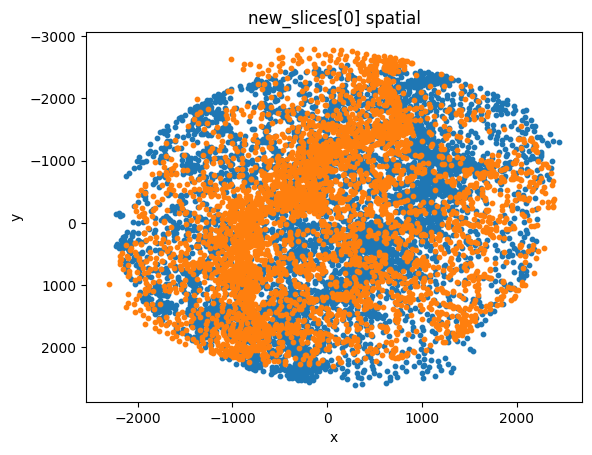

In [21]:
plt.scatter(new_slices[0].obsm['spatial'][:,0], new_slices[0].obsm['spatial'][:,1], s=10)
plt.scatter(new_slices[1].obsm['spatial'][:,0], new_slices[1].obsm['spatial'][:,1], s=10)

plt.gca().invert_yaxis()
plt.title("new_slices[0] spatial")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [30]:
new_slices[0]

AnnData object with n_obs × n_vars = 4671 × 16
    obs: 'Image', 'Object ID', 'Object type', 'Name', 'Classification', 'Parent', 'ROI', 'Centroid X µm', 'Centroid Y µm', 'Nucleus: Area', 'Nucleus: Perimeter', 'Nucleus: Circularity', 'Nucleus: Max caliper', 'Nucleus: Min caliper', 'Nucleus: Eccentricity', 'Nucleus: DAPI sum', 'Nucleus: DAPI std dev', 'Nucleus: DAPI max', 'Nucleus: DAPI min', 'Nucleus: DAPI range', 'Nucleus: CD8 sum', 'Nucleus: CD8 std dev', 'Nucleus: CD8 max', 'Nucleus: CD8 min', 'Nucleus: CD8 range', 'Nucleus: CD20 sum', 'Nucleus: CD20 std dev', 'Nucleus: CD20 max', 'Nucleus: CD20 min', 'Nucleus: CD20 range', 'Nucleus: CD4 sum', 'Nucleus: CD4 std dev', 'Nucleus: CD4 max', 'Nucleus: CD4 min', 'Nucleus: CD4 range', 'Nucleus: GZMB sum', 'Nucleus: GZMB std dev', 'Nucleus: GZMB max', 'Nucleus: GZMB min', 'Nucleus: GZMB range', 'Nucleus: FOXP3 sum', 'Nucleus: FOXP3 std dev', 'Nucleus: FOXP3 max', 'Nucleus: FOXP3 min', 'Nucleus: FOXP3 range', 'Nucleus: Ki67 sum', 'Nucleus: Ki

In [31]:

new_slices[0].write_h5ad("query_paste2_Prot_tongue.h5ad")
new_slices[1].write_h5ad("ref_paste2_RNA_tongue.h5ad")




In [15]:
refAD = sc.read_h5ad('ref_paste2_RNA_tongue.h5ad')
queryAD = sc.read_h5ad('query_paste2_Prot_tongue.h5ad')

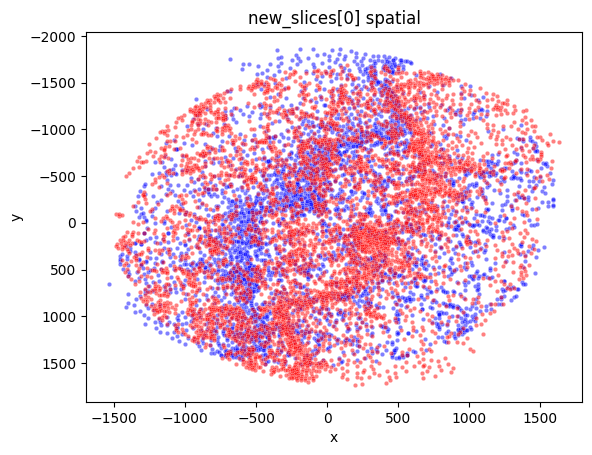

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(x=refAD.obsm['spatial'][:,0],y=refAD.obsm['spatial'][:,1],s=10, color='blue', alpha=0.5)
sns.scatterplot(x=queryAD.obsm['spatial'][:,0],y=queryAD.obsm['spatial'][:,1],s=10, color='red', alpha=0.5)
plt.gca().invert_yaxis()
plt.title("new_slices[0] spatial")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Text(0.5, 1.0, 'PASTE2')

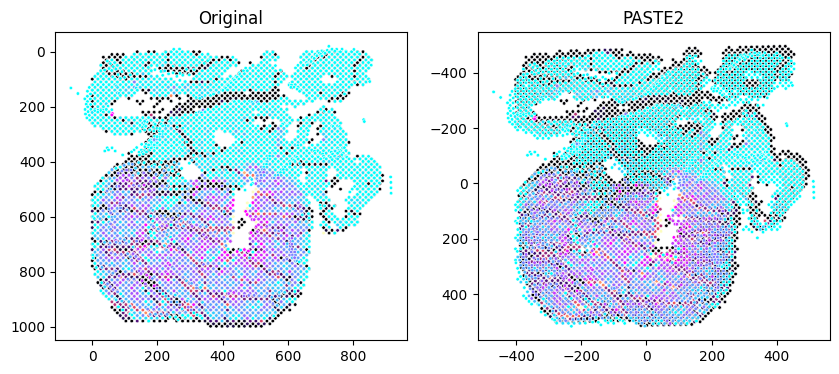

In [45]:
new_slices = [0,1]
slices = [refAD, queryAD]
#new_slices[0] = sc.read_h5ad("rep2AD_paste2.h5ad")
#new_slices[1] = sc.read_h5ad("rep1AD_paste2.h5ad")
new_slices[0] = sc.read_h5ad("rep2AD_paste2_valisStart_1120.h5ad")
new_slices[1] = sc.read_h5ad("rep1AD_paste2_valisStart_1120.h5ad")
ct = 'Cardiomyocytes_percentage'
fig, ax=plt.subplots(1,2,figsize=(10,4))
sz = 25
sns.scatterplot(x=slices[0].obsm['spatial'][:,0],y=slices[0].obsm['spatial'][:,1],s=sz, 
               marker=".",hue=slices[0].obs[ct], palette='magma', ax=ax[0])
sns.scatterplot(x=slices[1].obsm['spatial'][:,0],y=slices[1].obsm['spatial'][:,1],s=sz, marker=".",hue=slices[1].obs[ct], 
                palette='cool', ax=ax[0])
ax[0].invert_yaxis()
sns.scatterplot(x=new_slices[0].obsm['spatial'][:,0],y=new_slices[0].obsm['spatial'][:,1],s=sz, 
               marker=".",hue=new_slices[0].obs[ct], palette='magma', ax=ax[1])
sns.scatterplot(x=new_slices[1].obsm['spatial'][:,0],y=new_slices[1].obsm['spatial'][:,1],s=sz, marker=".",hue=new_slices[1].obs[ct],   palette='cool', ax=ax[1])
ax[1].invert_yaxis()
ax[0].get_legend().remove()
ax[1].get_legend().remove()
# ax[0].set_xticklabels([])
# ax[0].set_yticklabels([])
# ax[1].set_xticklabels([])
# ax[1].set_yticklabels([])
ax[0].set_title("Original")
ax[1].set_title("PASTE2")

In [46]:
new_ref = new_slices[0].obs.copy()
new_query = new_slices[1].obs.copy()


In [47]:
cell_types = ['Smooth muscle cells', 'Fibroblast', 'Atrial cardiomyocytes', 
                         'Cardiomyocytes', 'Endothelium', 'Epicardium', 
                         'Schwan progenitors', 'Ventricular cardiomyocytes']
cell_type_columns = [x+'_percentage' for x in cell_types]
# Function to find the dominant cell type
def get_dominant_cell_type(row):
    return cell_type_columns[row[cell_type_columns].argmax()]

new_ref['Dominant_Cell_Type'] = new_ref.apply(get_dominant_cell_type, axis=1)
new_query['Dominant_Cell_Type'] = new_query.apply(get_dominant_cell_type, axis=1)
new_ref['PASTE2_X'] = new_slices[0].obsm['spatial'][:,0]
new_ref['PASTE2_Y'] = new_slices[0].obsm['spatial'][:,1]
new_query['PASTE2_X'] = new_slices[1].obsm['spatial'][:,0]
new_query['PASTE2_Y'] = new_slices[1].obsm['spatial'][:,1]

In [48]:
new_query.PASTE2_X.min(), new_query.PASTE2_X.max(), new_ref.PASTE2_X.min(), new_ref.PASTE2_X.max()


(np.float64(-469.3616987050664),
 np.float64(513.7460226351336),
 np.float64(-401.9901990359419),
 np.float64(497.813265488617))

In [49]:
new_ref.head()

,spot_x,spot_y,cell_count,Endothelium_percentage,Atrial cardiomyocytes_percentage,Cardiomyocytes_percentage,Epicardium_percentage,Fibroblast_percentage,Schwan progenitors_percentage,Smooth muscle cells_percentage,Ventricular cardiomyocytes_percentage,Cell_Num,New_X,New_Y,Dominant_Cell_Type,PASTE2_X,PASTE2_Y
0,2760.274518,294.533333,1,100.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,138.0,0.0,Endothelium_percentage,-266.483379,-479.185257
1,3395.359814,294.533333,2,50.0,0.0,0.0,50.0,0.0,0.0,0.0,0.0,1,173.0,0.0,Endothelium_percentage,-231.493900,-480.043351
2,3712.902462,294.533333,1,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,2,190.0,0.0,Fibroblast_percentage,-214.499010,-480.460140
3,4347.987758,294.533333,2,0.0,0.0,0.0,100.0,0.0,0.0,0.0,0.0,3,225.0,0.0,Epicardium_percentage,-179.509530,-481.318235
4,4665.530406,294.533333,1,0.0,0.0,0.0,0.0,100.0,0.0,0.0,0.0,4,242.0,0.0,Fibroblast_percentage,-162.514640,-481.735024


In [50]:
new_query.head()

,spot_x,spot_y,cell_count,Smooth muscle cells_percentage,Fibroblast_percentage,Atrial cardiomyocytes_percentage,Cardiomyocytes_percentage,Endothelium_percentage,Epicardium_percentage,Schwan progenitors_percentage,Ventricular cardiomyocytes_percentage,Cell_Num,New_X,New_Y,Dominant_Cell_Type,PASTE2_X,PASTE2_Y
0,12922.839256,263.833333,4,75.000000,25.000000,0.0,0.0,0.0,0.0,0.0,0.0,0,657.516956,-0.133918,Smooth muscle cells_percentage,253.967192,-463.266663
1,13240.381904,263.833333,9,66.666667,33.333333,0.0,0.0,0.0,0.0,0.0,0.0,1,674.407621,-0.263716,Smooth muscle cells_percentage,270.857858,-463.396460
2,13557.924552,263.833333,4,75.000000,25.000000,0.0,0.0,0.0,0.0,0.0,0.0,2,692.380183,-0.377012,Smooth muscle cells_percentage,288.830419,-463.509757
3,13875.467200,263.833333,4,25.000000,75.000000,0.0,0.0,0.0,0.0,0.0,0.0,3,704.671579,-2.997449,Fibroblast_percentage,301.121815,-466.130194
4,14510.552496,263.833333,3,0.000000,100.000000,0.0,0.0,0.0,0.0,0.0,0.0,4,726.064387,-19.761782,Fibroblast_percentage,322.514623,-482.894527


In [51]:
def check_alignment(inDF1, inDF2, xcol, ycol):
    # List of cell type columns to check    
    # Create KDTree for efficient nearest neighbor search
    from scipy.spatial import cKDTree
    tree = cKDTree(inDF2[[xcol, ycol]])
    ct = 'Dominant_Cell_Type'
    # Find nearest neighbors and check if dominant cell types match
    distances, indices = tree.query(inDF1[[xcol, ycol]])
    #print(indices[1:10])
    inDF1['nearest_dominant_type'] = inDF2.iloc[indices][ct].values
    inDF1['type_match'] = inDF1[ct] == inDF1['nearest_dominant_type']

    # Calculate alignment score
    alignment_score = inDF1['type_match'].mean()
    
    print(f"Alignment score: {alignment_score:.2%}")
    
    return alignment_score, inDF1[[xcol, ycol, ct, 'nearest_dominant_type', 'type_match']]
ascore, outplot = check_alignment(new_query, new_ref, 'PASTE2_X', 'PASTE2_Y')

Alignment score: 52.04%


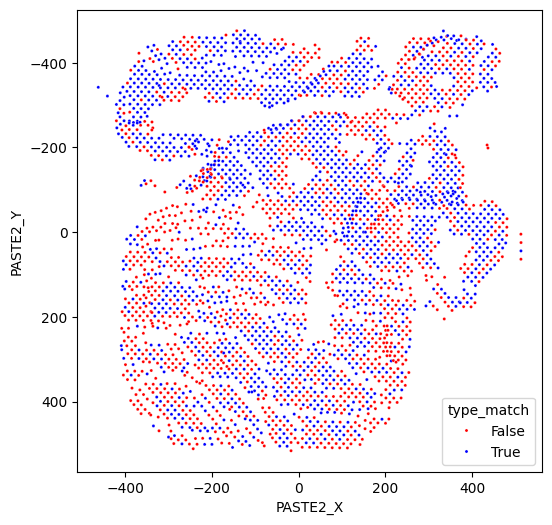

In [26]:
fig,ax=plt.subplots(figsize=(6,6))
sns.scatterplot(x=outplot.PASTE2_X, y=outplot.PASTE2_Y, hue=outplot.type_match, palette=['red','blue'],s=5)
ax.invert_yaxis()

KeyError: 'Dominant_Cell_Type'

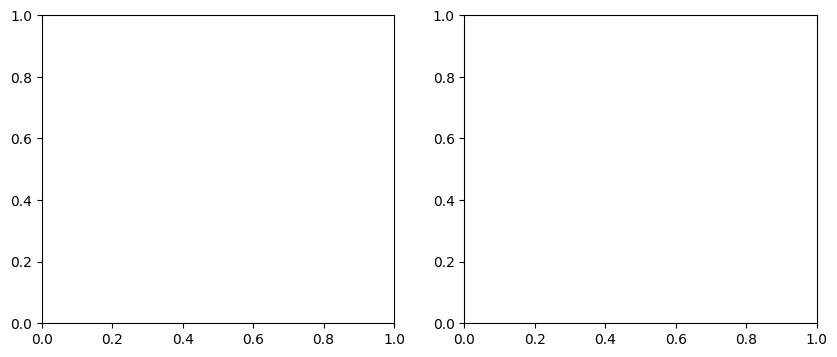

In [83]:

ct = 'Dominant_Cell_Type'
fig, ax=plt.subplots(1,2,figsize=(10,4))
sz = 25
sns.scatterplot(x=slices[0].obsm['spatial'][:,0],y=slices[0].obsm['spatial'][:,1],s=sz, 
               marker=".",hue=slices[0].obs[ct], palette='Set1', ax=ax[0])
sns.scatterplot(x=slices[1].obsm['spatial'][:,0],y=slices[1].obsm['spatial'][:,1],s=sz, marker=".",hue=slices[1].obs[ct], 
                palette='Set1', ax=ax[0])
ax[0].invert_yaxis()
sns.scatterplot(x=new_slices[0].obsm['spatial'][:,0],y=new_slices[0].obsm['spatial'][:,1],s=sz, 
               marker=".",hue=new_slices[0].obs[ct], palette='Set1', ax=ax[1])
sns.scatterplot(x=new_slices[1].obsm['spatial'][:,0],y=new_slices[1].obsm['spatial'][:,1],s=sz, marker=".",hue=new_slices[1].obs[ct],   palette='Set1', ax=ax[1])
ax[1].invert_yaxis()
ax[0].get_legend().remove()
ax[1].get_legend().remove()
ax[0].set_xticklabels([])
ax[0].set_yticklabels([])
ax[1].set_xticklabels([])
ax[1].set_yticklabels([])
ax[0].set_title("Original")
ax[1].set_title("PASTE2")

In [27]:

refAD.write_h5ad("rep2AD_valisStart.h5ad")
queryAD.write_h5ad("rep1AD_valisStart.h5ad")

In [7]:
slices2 = [refAD, queryAD]
pis2 = [pi_AB]
new_slices2 = projection.partial_stack_slices_pairwise(slices2, pis2)

new_slices[0].write_h5ad("rep2AD_paste2.h5ad")
new_slices[1].write_h5ad("rep1AD_paste2.h5ad")



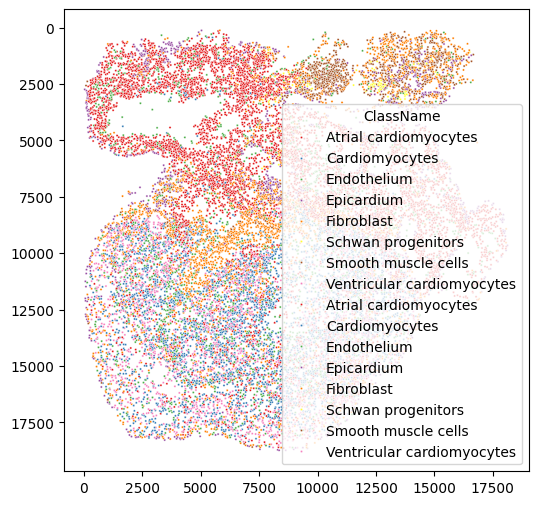

In [15]:
fig, ax=plt.subplots(figsize=(6,6))
sns.scatterplot(x=slices2[0].obsm['spatial'][:,0],y=slices2[0].obsm['spatial'][:,1],s=10, 
               marker=".",hue=slices2[0].obs['ClassName'], palette    ='Set1')
sns.scatterplot(x=slices2[1].obsm['spatial'][:,0],y=slices2[1].obsm['spatial'][:,1],s=10, marker=".",hue=slices2[1].obs['ClassName'], 
                palette='Set1')
ax.invert_yaxis()


Text(0.5, 1.0, 'PASTE2')

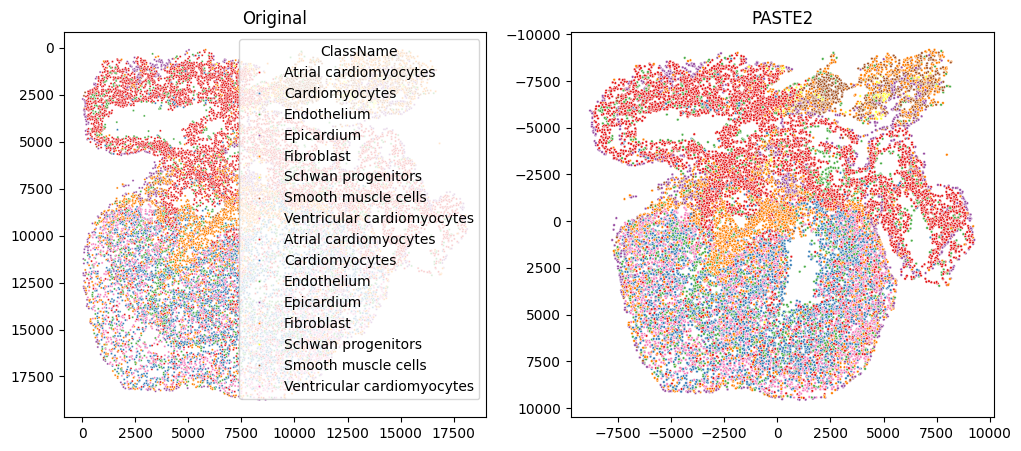

In [22]:
ct = 'ClassName'
fig, ax=plt.subplots(1,2,figsize=(12,5))
sns.scatterplot(x=slices2[0].obsm['spatial'][:,0],y=slices2[0].obsm['spatial'][:,1],s=10, 
               marker=".",hue=slices2[0].obs[ct], palette='Set1', ax=ax[0])
sns.scatterplot(x=slices2[1].obsm['spatial'][:,0],y=slices2[1].obsm['spatial'][:,1],s=10, marker=".",hue=slices2[1].obs[ct], 
                palette='Set1', ax=ax[0])
ax[0].invert_yaxis()
sns.scatterplot(x=new_slices2[0].obsm['spatial'][:,0],y=new_slices2[0].obsm['spatial'][:,1],s=15, 
               marker=".",hue=new_slices2[0].obs[ct], palette='Set1', ax=ax[1])
sns.scatterplot(x=new_slices2[1].obsm['spatial'][:,0],y=new_slices2[1].obsm['spatial'][:,1],s=15, marker=".",hue=new_slices2[1].obs[ct],   palette='Set1', ax=ax[1])
ax[1].invert_yaxis()
ax[1].get_legend().remove()
ax[0].set_title("Original")
ax[1].set_title("PASTE2")




In [25]:
new_slices2[0].obs['SampleName'] = 'rep2'
new_slices2[1].obs['SampleName'] = 'rep1'


In [28]:
slices2[0].obs['SampleName'] = 'rep2'
slices2[1].obs['SampleName'] = 'rep1'


Text(0.5, 1.0, 'PASTE2')

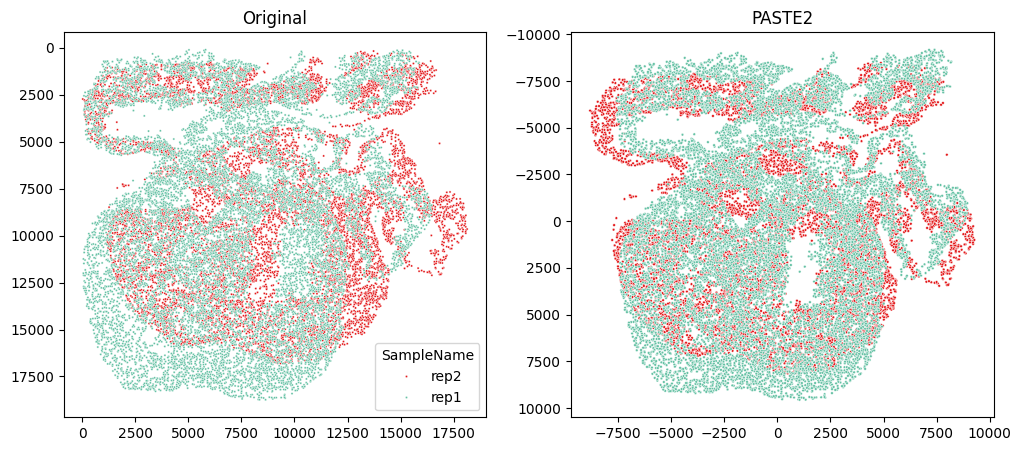

In [31]:
ct = 'SampleName'
fig, ax=plt.subplots(1,2,figsize=(12,5))
sns.scatterplot(x=slices2[0].obsm['spatial'][:,0],y=slices2[0].obsm['spatial'][:,1],s=10, 
               marker=".",hue=slices2[0].obs[ct], palette='Set1', ax=ax[0])
sns.scatterplot(x=slices2[1].obsm['spatial'][:,0],y=slices2[1].obsm['spatial'][:,1],s=10, marker=".",hue=slices2[1].obs[ct], 
                palette='Set2', ax=ax[0])
ax[0].invert_yaxis()
sns.scatterplot(x=new_slices2[0].obsm['spatial'][:,0],y=new_slices2[0].obsm['spatial'][:,1],s=15, 
               marker=".",hue=new_slices2[0].obs[ct], palette='Set1', ax=ax[1])
sns.scatterplot(x=new_slices2[1].obsm['spatial'][:,0],y=new_slices2[1].obsm['spatial'][:,1],s=15, marker=".",hue=new_slices2[1].obs[ct],   palette='Set2', ax=ax[1])
ax[1].invert_yaxis()
ax[1].get_legend().remove()
ax[0].set_title("Original")
ax[1].set_title("PASTE2")




In [32]:
new_slices2[0].write_h5ad("rep2AD_paste2_sc_05.h5ad")
new_slices2[1].write_h5ad("rep1AD_paste2_sc_05.h5ad")


Text(0.5, 1.0, 'PASTE2')

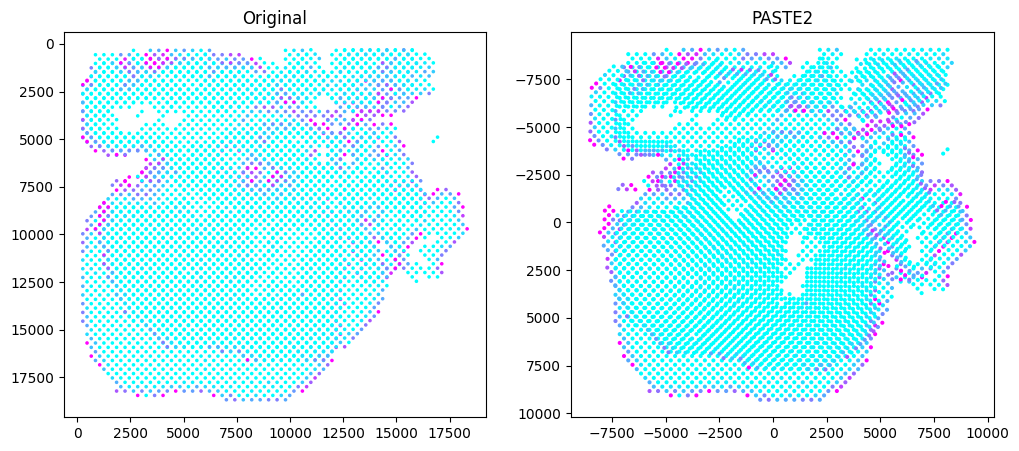

In [35]:
ct = 'Epicardium_percentage'
fig, ax=plt.subplots(1,2,figsize=(12,5))
ax[0].scatter(slices[0].obsm['spatial'][:,0],slices[0].obsm['spatial'][:,1],s=10, 
           marker=".",c=slices[0].obs[ct], cmap='cool')
ax[0].scatter(slices[1].obsm['spatial'][:,0],slices[1].obsm['spatial'][:,1],s=10, marker=".",c=slices[1].obs[ct], cmap='cool')
ax[0].invert_yaxis()
ax[1].scatter(new_slices[0].obsm['spatial'][:,0],new_slices[0].obsm['spatial'][:,1],s=15, 
           marker=".",c=new_slices[0].obs[ct], cmap='cool')
ax[1].scatter(new_slices[1].obsm['spatial'][:,0],new_slices[1].obsm['spatial'][:,1],s=15, marker=".",c=new_slices[1].obs[ct], cmap='cool')
ax[1].invert_yaxis()
ax[0].set_title("Original")
ax[1].set_title("PASTE2")


